# 03 — Modality Alignment
## NetsLab-5G-ORAN-IDD · V1

**Project:** *Robust Multimodal Intrusion Detection in 5G Open RAN*

**Purpose:** Join the cleaned window-level network dataset (`network_clean.csv`) with the cleaned radio telemetry dataset (`radio_clean.csv`) to produce a **paired multimodal dataset** (`multimodal_dataset.csv`) where each row represents one 1-second window with both network-side and radio-side features.

**Key design decisions and fixes applied here (from alignment review):**

| Issue | Fix |
|---|---|
| Scenario name mismatch | Radio uses `DDOS_ICMP1`; network uses `DDOSICMP1`. Map radio names → network names before joining. |
| Many radio rows per second | Aggregate radio KPIs per second across UEs (mean/std/count) before joining. |
| `dlBytes`/`ulBytes` cumulative | Convert to per-second deltas per `(scenario, ue_id)` before aggregation. |
| Duplicate radio rows | Drop true duplicates (identical `(scenario, ue_id, timestamp_ms)`) before aggregating. |
| `is_partial` filter | Keep flagged PortScan windows (too short to have full windows). Filter only `aug_phase_s != 0`. |
| IST +1 h offset | Applied in `01b` to `window_start_epoch_utc`; verified here vs. radio timestamps. |
| Inner join (no zero-fill) | Join only where a network window exists; report unmatched counts. |

**Outputs:**
- `multimodal_dataset.csv` — paired rows, one per network window that has at least one radio measurement in the same second.
- `alignment_report.csv` — per-scenario alignment summary (network windows, matched, unmatched).


---
## 1 · Configuration and Paths

In [6]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80, "display.width", 250,
              "display.max_rows", 120, "display.float_format", "{:,.4f}".format)

# ---- locate input files ------------------------------------------------
# Adjust these paths to wherever 01b and 02b saved their outputs.
OUT_ROOT = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.environ.get("NETSLAB_OUT", "./outputs")

NETWORK_CLEAN_PATH   = os.path.join("/kaggle/input/datasets/omarelwekeil1/network-clean/network_clean.csv")
RADIO_CLEAN_PATH     = os.path.join("/kaggle/input/datasets/omarelwekeil1/radio-clean/radio_clean.csv")
FEATURE_COLS_PATH    = os.path.join("/kaggle/input/datasets/omarelwekeil1/network-features/network_feature_columns.json")

for p in [NETWORK_CLEAN_PATH, RADIO_CLEAN_PATH]:
    if not os.path.isfile(p):
        raise FileNotFoundError(f"Required input not found: {p}\n"
                                "Run 01b_Network_cleaning.ipynb and 02b_Radio_cleaning.ipynb first.")

# ---- output location ---------------------------------------------------
OUT = OUT_ROOT
os.makedirs(OUT, exist_ok=True)
print("NETWORK_CLEAN_PATH :", NETWORK_CLEAN_PATH)
print("RADIO_CLEAN_PATH   :", RADIO_CLEAN_PATH)
print("Output dir         :", OUT)

NETWORK_CLEAN_PATH : /kaggle/input/datasets/omarelwekeil1/network-clean/network_clean.csv
RADIO_CLEAN_PATH   : /kaggle/input/datasets/omarelwekeil1/radio-clean/radio_clean.csv
Output dir         : /kaggle/working


---
## 2 · Load Input Datasets

In [7]:
# ---- network_clean.csv (window-level, one row per 1-s window) ----------
net = pd.read_csv(NETWORK_CLEAN_PATH)
print(f"network_clean : {net.shape[0]:,} rows × {net.shape[1]} cols")

# ---- radio_clean.csv (per-UE, ~1 Hz, may be multiple rows per second) --
radio = pd.read_csv(RADIO_CLEAN_PATH)
print(f"radio_clean   : {radio.shape[0]:,} rows × {radio.shape[1]} cols")

# quick sanity
print("\nNetwork scenarios:", sorted(net.scenario.unique()))
print("Radio scenarios  :", sorted(radio.scenario.unique()))

network_clean : 4,190 rows × 45 cols
radio_clean   : 7,490 rows × 53 cols

Network scenarios: ['Benign1', 'Benign2', 'Benign3', 'Benign4', 'Benign5', 'Benign6', 'DDOSICMP1', 'DDOSICMP2', 'DDOSICMP3', 'DDOSSYN1', 'DDOSSYN2', 'DDOSSYN3', 'DDOSTCP1', 'DDOSTCP2', 'DDOSTCP3', 'DDOSUDP1', 'DDOSUDP2', 'DDOSUDP3', 'ICMP1', 'ICMP2', 'ICMP3', 'PortScan1', 'PortScan2', 'PortScan3', 'SYN1', 'SYN2', 'SYN3', 'TCP1', 'TCP2', 'TCP3', 'UDP1', 'UDP2', 'UDP3', 'UDP4', 'UDP5']
Radio scenarios  : ['Benign1', 'Benign2', 'Benign3', 'Benign4', 'Benign5', 'Benign6', 'DDOS_ICMP1', 'DDOS_ICMP2', 'DDOS_ICMP3', 'DDOS_SYN1', 'DDOS_SYN2', 'DDOS_SYN3', 'DDOS_TCP1', 'DDOS_TCP2', 'DDOS_TCP3', 'DDOS_UDP1', 'DDOS_UDP2', 'DDOS_UDP3', 'ICMP1', 'ICMP2', 'ICMP3', 'PortScan1', 'PortScan2', 'PortScan3', 'SYN1', 'SYN2', 'SYN3', 'TCP1', 'TCP2', 'TCP3', 'UDP1', 'UDP2', 'UDP3', 'UDP4', 'UDP5']


---
## 3 · Fix 1 — Scenario Name Normalisation

The network notebook uses `DDOSICMP1` (no underscore) while the radio notebook uses `DDOS_ICMP1` (with underscore). Without fixing this the join silently loses all 12 DDoS scenarios (≈37 % of radio rows).

Strategy: add `scenario_net` column to radio that strips the underscore from DDoS names.

In [8]:
def radio_to_net_scenario(s):
    """Map radio scenario name to network scenario name.
    Radio: DDOS_ICMP1  → Network: DDOSICMP1
    Radio: DDOS_SYN1   → Network: DDOSSYN1
    Radio: DDOS_TCP1   → Network: DDOSTCP1
    Radio: DDOS_UDP1   → Network: DDOSUDP1
    Others are identical.
    """
    return s.replace("DDOS_", "DDOS")  # DDOS_ICMP1 → DDOSICMP1

radio["scenario_net"] = radio["scenario"].apply(radio_to_net_scenario)

# Verify coverage
net_scenarios   = set(net.scenario.unique())
radio_net_scens = set(radio.scenario_net.unique())
missing = net_scenarios - radio_net_scens
extra   = radio_net_scens - net_scenarios
print(f"Network scenarios : {len(net_scenarios)}")
print(f"Radio (mapped)    : {len(radio_net_scens)}")
print(f"Missing from radio (after mapping): {missing}")
print(f"Extra in radio (not in network)   : {extra}")
print("\nRadio → network name sample:")
print(radio[["scenario", "scenario_net"]].drop_duplicates().sort_values("scenario_net").to_string(index=False))

Network scenarios : 35
Radio (mapped)    : 35
Missing from radio (after mapping): set()
Extra in radio (not in network)   : set()

Radio → network name sample:
  scenario scenario_net
   Benign1      Benign1
   Benign2      Benign2
   Benign3      Benign3
   Benign4      Benign4
   Benign5      Benign5
   Benign6      Benign6
DDOS_ICMP1    DDOSICMP1
DDOS_ICMP2    DDOSICMP2
DDOS_ICMP3    DDOSICMP3
 DDOS_SYN1     DDOSSYN1
 DDOS_SYN2     DDOSSYN2
 DDOS_SYN3     DDOSSYN3
 DDOS_TCP1     DDOSTCP1
 DDOS_TCP2     DDOSTCP2
 DDOS_TCP3     DDOSTCP3
 DDOS_UDP1     DDOSUDP1
 DDOS_UDP2     DDOSUDP2
 DDOS_UDP3     DDOSUDP3
     ICMP1        ICMP1
     ICMP2        ICMP2
     ICMP3        ICMP3
 PortScan1    PortScan1
 PortScan2    PortScan2
 PortScan3    PortScan3
      SYN1         SYN1
      SYN2         SYN2
      SYN3         SYN3
      TCP1         TCP1
      TCP2         TCP2
      TCP3         TCP3
      UDP1         UDP1
      UDP2         UDP2
      UDP3         UDP3
      UDP4         UDP4


---
## 4 · Fix 2 — `dlBytes` / `ulBytes` Cumulative Counter → Per-Second Deltas

The radio counters `dlBytes` and `ulBytes` are cumulative within each `(scenario, ue_id)` session. Using raw values would leak time-ordering and scenario identity into the model features. We compute first-differences per `(scenario, ue_id)` to get bytes transferred in each 1-second interval.

In [9]:
COUNTER_COLS = ["dlBytes", "ulBytes"]

# Sort by scenario, ue_id, timestamp_ms before diffing
radio = radio.sort_values(["scenario", "ue_id", "timestamp_ms"]).reset_index(drop=True)

for col in COUNTER_COLS:
    # Compute first difference within each (scenario, ue_id) group
    radio[f"{col}_delta"] = (
        radio.groupby(["scenario", "ue_id"])[col]
             .diff()
             .clip(lower=0)   # negative diff = counter reset or new session; treat as 0
    )

DELTA_COLS = [f"{c}_delta" for c in COUNTER_COLS]
print("Delta column summary (non-null rows, range):")
for c in DELTA_COLS:
    s = radio[c].dropna()
    print(f"  {c:20s}: {len(s):,} non-null  min={s.min():,.0f}  max={s.max():,.0f}  median={s.median():,.0f}")

Delta column summary (non-null rows, range):
  dlBytes_delta       : 7,430 non-null  min=0  max=13,986,127  median=45,620
  ulBytes_delta       : 7,430 non-null  min=0  max=2,910,317  median=38,730


---
## 5 · Fix 3 — Drop Duplicate Radio Rows Before Aggregation

There are 70 flagged duplicates (35 pairs, one per scenario). We drop exact duplicates on `(scenario, ue_id, timestamp_ms)` before aggregating, keeping the first occurrence.

In [10]:
n_before = len(radio)
radio_dedup = radio.drop_duplicates(subset=["scenario", "ue_id", "timestamp_ms"], keep="first")
n_after = len(radio_dedup)
print(f"Rows before dedup : {n_before:,}")
print(f"Rows after  dedup : {n_after:,}  (removed {n_before - n_after:,} duplicates)")

# Verify: each scenario lost exactly 1 row (one duplicate pair → keep 1)
dup_per_scenario = radio.groupby("scenario")["is_duplicate"].sum()
print("\nFlagged duplicate rows per scenario (should all be 2):")
print(dup_per_scenario[dup_per_scenario > 0].to_string())
print(f"\nTotal duplicate flags: {dup_per_scenario.sum():.0f}")

Rows before dedup : 7,490
Rows after  dedup : 7,455  (removed 35 duplicates)

Flagged duplicate rows per scenario (should all be 2):
scenario
Benign1       2
Benign2       2
Benign3       2
Benign4       2
Benign5       2
Benign6       2
DDOS_ICMP1    2
DDOS_ICMP2    2
DDOS_ICMP3    2
DDOS_SYN1     2
DDOS_SYN2     2
DDOS_SYN3     2
DDOS_TCP1     2
DDOS_TCP2     2
DDOS_TCP3     2
DDOS_UDP1     2
DDOS_UDP2     2
DDOS_UDP3     2
ICMP1         2
ICMP2         2
ICMP3         2
PortScan1     2
PortScan2     2
PortScan3     2
SYN1          2
SYN2          2
SYN3          2
TCP1          2
TCP2          2
TCP3          2
UDP1          2
UDP2          2
UDP3          2
UDP4          2
UDP5          2

Total duplicate flags: 70


---
## 6 · Fix 4 — Aggregate Radio to 1-Second Windows

Benign and DDoS scenarios have ~2 UE rows per second; DoS has ~1. We aggregate all numeric KPIs per `(scenario_net, timestamp_s)` using mean (and std for variability). We also retain UE count (`ue_count`) as a feature — it discriminates DoS (single UE) from DDoS (multiple UEs) — and exclude `ue_id`, `rnti_int`, `cellid` from model features (they identify the capture).

**Aggregation rules:**
- KPI measurements: `mean`, `std` across UEs in the same second
- Byte deltas: `sum` across UEs (total bytes in that second)
- UE count: `nunique` on `ue_id`

In [11]:
# KPIs to aggregate
KPI_COLS = ["rsrp", "rssi", "rsrq", "sinr", "cqi", "dlMcs", "ulMcs",
            "dlBler", "ulBler", "ri", "phr", "pcmax", "pucchSnr", "puschSnr"]

# Build aggregation dict
agg_dict = {}
for k in KPI_COLS:
    if k in radio_dedup.columns:
        agg_dict[f"{k}_mean"] = pd.NamedAgg(column=k, aggfunc="mean")
        agg_dict[f"{k}_std"]  = pd.NamedAgg(column=k, aggfunc="std")

for c in DELTA_COLS:
    if c in radio_dedup.columns:
        # Sum of byte deltas across UEs = total bytes for that second
        agg_dict[c.replace("_delta", "_per_s")] = pd.NamedAgg(column=c, aggfunc="sum")

agg_dict["ue_count"] = pd.NamedAgg(column="ue_id", aggfunc="nunique")
# Preserve label columns (all identical within a scenario)
agg_dict["class_fm"]  = pd.NamedAgg(column="class_fm",  aggfunc="first")
agg_dict["is_attack"] = pd.NamedAgg(column="is_attack", aggfunc="first")
agg_dict["family"]    = pd.NamedAgg(column="family",    aggfunc="first")
agg_dict["mode"]      = pd.NamedAgg(column="mode",      aggfunc="first")

radio_agg = (
    radio_dedup
    .groupby(["scenario_net", "timestamp_s"], sort=False)
    .agg(**agg_dict)
    .reset_index()
)

# Fill std NaN (single UE in that second) with 0
std_cols = [c for c in radio_agg.columns if c.endswith("_std")]
radio_agg[std_cols] = radio_agg[std_cols].fillna(0.0)

print(f"radio_agg shape: {radio_agg.shape}")
print("\nPer-class row counts in aggregated radio:")
print(radio_agg.groupby("class_fm").size().sort_index().to_frame("agg_rows"))

radio_agg shape: (4590, 37)

Per-class row counts in aggregated radio:
           agg_rows
class_fm           
Benign         1515
ICMP_DDoS       336
ICMP_DoS        354
PortScan         23
SYN_DDoS        331
SYN_DoS         372
TCP_DDoS        337
TCP_DoS         370
UDP_DDoS        335
UDP_DoS         617


---
## 7 · Fix 5 — Prepare Network Side

Filter network_clean to:
- Real windows only (`aug_phase_s == 0` or `is_synthetic == 0`)
- Keep `is_partial == 1` rows for PortScan (the captures are too short to have full windows)

Add `timestamp_s` as integer epoch for the join key.

In [12]:
# network_clean.csv already contains only real (non-augmented) windows
# and already has is_partial handled correctly (PortScan partial windows kept).
# We just confirm and add timestamp_s for joining.

print(f"network_clean rows: {len(net):,}")
print(f"  is_partial==1 rows: {(net.is_partial==1).sum()}  (PortScan edge windows)")
if 'aug_phase_s' in net.columns:
    print(f"  aug_phase_s != 0 rows: {(net.aug_phase_s != 0).sum()} (should be 0 — clean file has no augmented)")

# Add integer timestamp_s as join key
net["timestamp_s"] = net["window_start_epoch_utc"].astype("Int64")

# Confirm no nulls on join keys
assert net["scenario"].notna().all(), "null scenario in network_clean"
assert net["timestamp_s"].notna().all(), "null timestamp_s in network_clean"
print(f"\nJoin key ready: scenario × timestamp_s  ({net[['scenario','timestamp_s']].drop_duplicates().shape[0]:,} unique pairs)")

network_clean rows: 4,190
  is_partial==1 rows: 6  (PortScan edge windows)

Join key ready: scenario × timestamp_s  (4,190 unique pairs)


---
## 8 · IST +1 h Offset Verification

Before joining we verify the timezone alignment. `network_clean.csv` already corrects IST timestamps by subtracting 3600 s. We check that Benign network windows fall inside the radio telemetry time span.

In [13]:
# Radio timestamps are raw epoch-ms; radio_clean uses UTC directly (no offset applied)
# network_clean already applied the IST -3600 s correction

print("=== Benign alignment check (IST +1 h offset) ===")
benign_net   = net[net.family == "Benign"]
benign_radio = radio[radio.family == "Benign"]

net_tmin  = benign_net["window_start_epoch_utc"].min()
net_tmax  = benign_net["window_start_epoch_utc"].max()
rad_tmin  = benign_radio["timestamp_ms"].min() / 1000
rad_tmax  = benign_radio["timestamp_ms"].max() / 1000

print(f"  Network Benign UTC span : {pd.Timestamp(net_tmin, unit='s', tz='UTC')} → {pd.Timestamp(net_tmax, unit='s', tz='UTC')}")
print(f"  Radio   Benign UTC span : {pd.Timestamp(rad_tmin, unit='s', tz='UTC')} → {pd.Timestamp(rad_tmax, unit='s', tz='UTC')}")

overlap_ok = net_tmin >= rad_tmin and net_tmax <= rad_tmax + 10  # 10 s slack
print(f"  Overlap OK (network inside radio span): {overlap_ok}")
if not overlap_ok:
    print("  WARNING: network windows fall outside radio telemetry span — check timezone offset!")

# Per-scenario summary for DDoS families
print("\n=== Per-scenario time span comparison ===")
for scn in sorted(net.scenario.unique()):
    n = net[net.scenario == scn]
    r_scn = radio[radio.scenario_net == scn]
    if r_scn.empty:
        print(f"  {scn:<14s} radio: (no rows)")
        continue
    n_t0 = n.window_start_epoch_utc.min()
    n_t1 = n.window_start_epoch_utc.max()
    r_t0 = r_scn.timestamp_ms.min() / 1000
    r_t1 = r_scn.timestamp_ms.max() / 1000
    lag  = round(n_t0 - r_t0, 1)
    print(f"  {scn:<14s} net=[{n_t0:.0f},{n_t1:.0f}]  radio=[{r_t0:.0f},{r_t1:.0f}]  lag={lag:+.1f}s")

=== Benign alignment check (IST +1 h offset) ===
  Network Benign UTC span : 2025-04-14 12:34:44+00:00 → 2025-04-14 13:19:02+00:00
  Radio   Benign UTC span : 2025-04-14 12:34:37.522000074+00:00 → 2025-04-14 13:19:01.522000074+00:00
  Overlap OK (network inside radio span): True

=== Per-scenario time span comparison ===
  Benign1        net=[1744634084,1744634205]  radio=[1744634078,1744634205]  lag=+6.5s
  Benign2        net=[1744634418,1744634731]  radio=[1744634414,1744634732]  lag=+4.5s
  Benign3        net=[1744635035,1744635330]  radio=[1744635028,1744635330]  lag=+7.5s
  Benign4        net=[1744635554,1744635855]  radio=[1744635551,1744635855]  lag=+3.5s
  Benign5        net=[1744636116,1744636268]  radio=[1744636113,1744636268]  lag=+3.5s
  Benign6        net=[1744636449,1744636742]  radio=[1744636439,1744636742]  lag=+10.5s
  DDOSICMP1      net=[1743693608,1743693708]  radio=[1743693605,1743693711]  lag=+3.1s
  DDOSICMP2      net=[1743693787,1743693894]  radio=[1743693783,174

---
## 9 · Inner Join — Pair Network Windows with Radio Measurements

Join on `scenario × timestamp_s`. We use an **inner join** to keep only windows where both modalities have data. Zero-filling radio seconds with no measurement would create a systematic "idle = benign" shortcut.

In [14]:
# Rename radio aggregated scenario column to match network
radio_agg_join = radio_agg.rename(columns={"scenario_net": "scenario"})

# Select radio columns to bring in (drop label cols already in network)
radio_feature_cols = (
    [c for c in radio_agg_join.columns
     if c not in {"scenario", "timestamp_s", "class_fm", "is_attack", "family", "mode"}]
)

paired = net.merge(
    radio_agg_join[["scenario", "timestamp_s"] + radio_feature_cols],
    on=["scenario", "timestamp_s"],
    how="inner",
    suffixes=("_net", "_radio")
)

print(f"network windows     : {len(net):,}")
print(f"paired rows (inner) : {len(paired):,}")
print(f"unmatched network   : {len(net) - len(paired):,} ({100*(len(net)-len(paired))/len(net):.1f}%)")
print(f"paired columns      : {paired.shape[1]}")

network windows     : 4,190
paired rows (inner) : 4,139
unmatched network   : 51 (1.2%)
paired columns      : 77


---
## 10 · Alignment Report — Per-Scenario Coverage

In [15]:
report_rows = []
for scn in sorted(net.scenario.unique()):
    net_scn   = net[net.scenario == scn]
    pair_scn  = paired[paired.scenario == scn]
    rad_scn   = radio_agg_join[radio_agg_join.scenario == scn]
    report_rows.append({
        "scenario"             : scn,
        "class_fm"             : net_scn.class_fm.iloc[0] if len(net_scn) else "",
        "net_windows"          : len(net_scn),
        "radio_agg_seconds"    : len(rad_scn),
        "paired_windows"       : len(pair_scn),
        "unmatched_net"        : len(net_scn) - len(pair_scn),
        "pct_matched"          : round(100 * len(pair_scn) / max(len(net_scn), 1), 1),
    })

report = pd.DataFrame(report_rows)
print("=== Alignment Report ===")
print(report.to_string(index=False))

report.to_csv(os.path.join(OUT, "alignment_report.csv"), index=False)
print(f"\nSaved: {os.path.join(OUT, 'alignment_report.csv')}")

=== Alignment Report ===
 scenario  class_fm  net_windows  radio_agg_seconds  paired_windows  unmatched_net  pct_matched
  Benign1    Benign          122                128             121              1      99.2000
  Benign2    Benign          235                319             235              0     100.0000
  Benign3    Benign          178                303             177              1      99.4000
  Benign4    Benign          230                305             229              1      99.6000
  Benign5    Benign          153                156             152              1      99.3000
  Benign6    Benign          271                304             270              1      99.6000
DDOSICMP1 ICMP_DDoS          101                107             101              0     100.0000
DDOSICMP2 ICMP_DDoS          108                115             108              0     100.0000
DDOSICMP3 ICMP_DDoS          109                114             109              0     100.0000
 DDOSSYN1  SYN_

---
## 11 · Integrity Checks

In [16]:
# Load network feature columns from JSON (produced by 01b)
try:
    with open(FEATURE_COLS_PATH) as f:
        fc = json.load(f)
    NET_FEATURE_COLS = fc["feature_cols"]
except FileNotFoundError:
    # Fallback: infer from network_clean columns
    _skip = {"window_id","scenario","family","mode","class_fm","is_attack",
             "window_start_epoch_utc","window_start_utc","window_start_wall_epoch",
             "tz_label","tz_offset_assumed_s","t_rel_s","coverage_s","is_partial",
             "timestamp_s","diag_ttl_mean","diag_tcp_win_mean"}
    NET_FEATURE_COLS = [c for c in net.columns if c not in _skip]
    print(f"network_feature_columns.json not found — inferred {len(NET_FEATURE_COLS)} feature cols")

RADIO_KPI_MEAN_COLS = [f"{k}_mean" for k in
                       ["rsrp","rssi","rsrq","sinr","cqi","dlMcs","ulMcs",
                        "dlBler","ulBler","ri","phr","pcmax","pucchSnr","puschSnr"]
                       if f"{k}_mean" in paired.columns]

checks = {
    "paired rows > 0"                        : len(paired) > 0,
    "no null window_id"                      : paired.window_id.notna().all(),
    "no null scenario"                       : paired.scenario.notna().all(),
    "no null class_fm"                       : paired.class_fm.notna().all(),
    "no null timestamp_s"                    : paired.timestamp_s.notna().all(),
    "is_attack in {0,1}"                     : set(paired.is_attack.unique()).issubset({0,1}),
    "NaN in net feature cols"                : int(paired[NET_FEATURE_COLS].isna().sum().sum()) == 0,
    "NaN in radio KPI mean cols"             : int(paired[RADIO_KPI_MEAN_COLS].isna().sum().sum()) == 0,
    "no negative ue_count"                   : (paired.ue_count >= 1).all(),
    "all classes represented"                : paired.class_fm.nunique() >= 2,
}

failed = {k: v for k, v in checks.items() if not v}
passed = {k: v for k, v in checks.items() if v}
for k in passed: print(f"  PASS  {k}")
for k in failed: print(f"  FAIL  {k}")
if failed:
    raise AssertionError(f"Integrity checks failed: {list(failed.keys())}")
print("\nAll integrity checks passed.")

  PASS  paired rows > 0
  PASS  no null window_id
  PASS  no null scenario
  PASS  no null class_fm
  PASS  no null timestamp_s
  PASS  is_attack in {0,1}
  PASS  NaN in net feature cols
  PASS  NaN in radio KPI mean cols
  PASS  no negative ue_count
  PASS  all classes represented

All integrity checks passed.


---
## 12 · Class Distribution in Paired Dataset

=== Class distribution in multimodal_dataset ===
 class_fm  is_attack  windows  scenarios  ue_count_median
   Benign          0     1184          6           2.0000
ICMP_DDoS          1      318          3           2.0000
 ICMP_DoS          1      350          3           1.0000
 PortScan          1        8          3           1.0000
 SYN_DDoS          1      314          3           2.0000
  SYN_DoS          1      362          3           1.0000
 TCP_DDoS          1      315          3           2.0000
  TCP_DoS          1      362          3           1.0000
 UDP_DDoS          1      316          3           2.0000
  UDP_DoS          1      610          5           1.0000


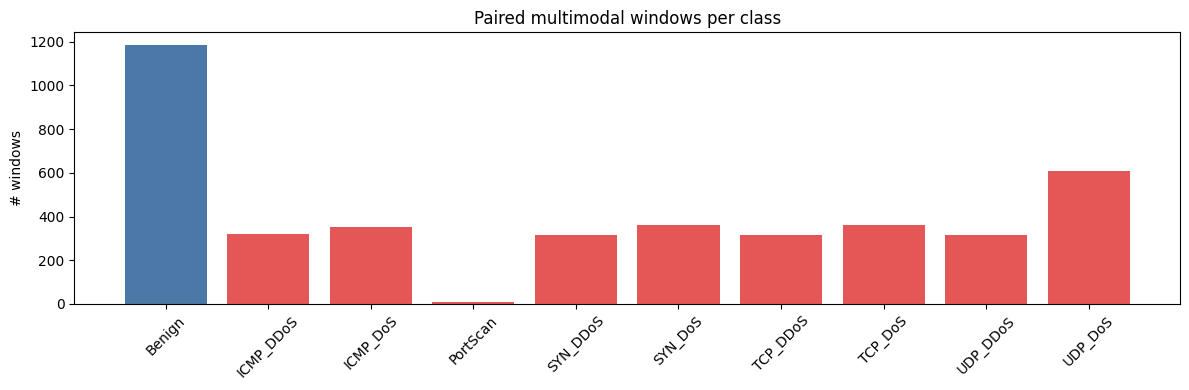

In [17]:
print("=== Class distribution in multimodal_dataset ===")
dist = (
    paired.groupby(["class_fm","is_attack"])
          .agg(windows=("window_id","size"),
               scenarios=("scenario","nunique"),
               ue_count_median=("ue_count","median"))
          .reset_index()
          .sort_values("class_fm")
)
print(dist.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4))
colors = ["#4c78a8" if r.is_attack == 0 else "#e45756" for _, r in dist.iterrows()]
ax.bar(dist.class_fm, dist.windows, color=colors)
ax.set_title("Paired multimodal windows per class")
ax.set_ylabel("# windows")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(OUT, "multimodal_class_counts.png"), dpi=110)
plt.show()

---
## 13 · UE Count Distribution (DoS vs DDoS diagnostic)

DoS attacks use a single UE (`ue_count == 1`); DDoS uses multiple UEs. This is a useful diagnostic — it should NOT be used as a model feature because it can directly identify the attack mode.

In [18]:
print("=== ue_count per class (median) ===")
print(paired.groupby("class_fm")["ue_count"]
           .value_counts()
           .unstack(fill_value=0)
           .to_string())

print("\nNote: ue_count is a diagnostic — do NOT include in model features.")

=== ue_count per class (median) ===
ue_count     1     2   3
class_fm                
Benign      32  1152   0
ICMP_DDoS    0   290  28
ICMP_DoS   350     0   0
PortScan     8     0   0
SYN_DDoS     0   314   0
SYN_DoS    362     0   0
TCP_DDoS     2   313   0
TCP_DoS    362     0   0
UDP_DDoS     0   278  38
UDP_DoS    610     0   0

Note: ue_count is a diagnostic — do NOT include in model features.


---
## 14 · Assemble Final Column Order and Save

**Column groups in `multimodal_dataset.csv`:**
1. **Identifiers & labels** — `window_id, scenario, family, mode, class_fm, is_attack`
2. **Time** — `timestamp_s, window_start_epoch_utc, window_start_utc, t_rel_s, coverage_s, is_partial`
3. **Network features** (29 from 01b) — `pkts, bytes, mean_len, ...`
4. **Radio KPI means** across UEs in the window
5. **Radio KPI stds** across UEs (spread = 0 for DoS single-UE)
6. **Radio byte throughput** (`dlBytes_per_s, ulBytes_per_s`)
7. **UE count** (diagnostic only — excluded from MULTIMODAL_FEATURE_COLS)
8. **Diagnostic** — `diag_ttl_mean, diag_tcp_win_mean` (network-side, NOT for models)

In [19]:
# ---- build column order ------------------------------------------------
ID_COLS   = ["window_id","scenario","family","mode","class_fm","is_attack"]
TIME_COLS = [c for c in ["timestamp_s","window_start_epoch_utc","window_start_utc",
                          "window_start_wall_epoch","tz_label","tz_offset_assumed_s",
                          "t_rel_s","coverage_s","is_partial"] if c in paired.columns]

RADIO_MEAN_COLS  = [c for c in radio_agg_join.columns if c.endswith("_mean")]
RADIO_STD_COLS   = [c for c in radio_agg_join.columns if c.endswith("_std")]
RADIO_BYTES_COLS = [c for c in radio_agg_join.columns if c.endswith("_per_s")]
DIAG_COLS        = [c for c in ["diag_ttl_mean","diag_tcp_win_mean"] if c in paired.columns]

FINAL_COLS = (
    ID_COLS
    + TIME_COLS
    + [c for c in NET_FEATURE_COLS if c in paired.columns]
    + RADIO_MEAN_COLS
    + RADIO_STD_COLS
    + RADIO_BYTES_COLS
    + ["ue_count"]
    + DIAG_COLS
)
# keep only columns that actually exist
FINAL_COLS = [c for c in FINAL_COLS if c in paired.columns]
# drop duplicates while preserving order
seen = set(); FINAL_COLS = [c for c in FINAL_COLS if not (c in seen or seen.add(c))]

MULTIMODAL = paired[FINAL_COLS].sort_values("window_start_epoch_utc").reset_index(drop=True)

# ---- feature column lists for downstream notebooks --------------------
MULTIMODAL_FEATURE_COLS = (
    [c for c in NET_FEATURE_COLS  if c in MULTIMODAL.columns]
    + RADIO_MEAN_COLS
    + RADIO_STD_COLS
    + RADIO_BYTES_COLS
    # ue_count intentionally excluded — it's a diagnostic not a model feature
)

print(f"multimodal_dataset shape: {MULTIMODAL.shape}")
print(f"  ID/label cols          : {len(ID_COLS)}")
print(f"  Time cols              : {len(TIME_COLS)}")
print(f"  Network feature cols   : {len([c for c in NET_FEATURE_COLS if c in MULTIMODAL.columns])}")
print(f"  Radio mean cols        : {len(RADIO_MEAN_COLS)}")
print(f"  Radio std  cols        : {len(RADIO_STD_COLS)}")
print(f"  Radio bytes cols       : {len(RADIO_BYTES_COLS)}")
print(f"  Total multimodal feat  : {len(MULTIMODAL_FEATURE_COLS)}")
print(f"  Diagnostic cols        : {len(DIAG_COLS)}")

multimodal_dataset shape: (4139, 77)
  ID/label cols          : 6
  Time cols              : 9
  Network feature cols   : 29
  Radio mean cols        : 14
  Radio std  cols        : 14
  Radio bytes cols       : 2
  Total multimodal feat  : 59
  Diagnostic cols        : 2


In [20]:
# ---- save outputs -------------------------------------------------------
multimodal_path = os.path.join(OUT, "multimodal_dataset.csv")
MULTIMODAL.to_csv(multimodal_path, index=False)
print(f"Saved: {multimodal_path}  {MULTIMODAL.shape}")

# Save feature column metadata
meta = {
    "multimodal_feature_cols" : MULTIMODAL_FEATURE_COLS,
    "net_feature_cols"        : [c for c in NET_FEATURE_COLS if c in MULTIMODAL.columns],
    "radio_mean_cols"         : RADIO_MEAN_COLS,
    "radio_std_cols"          : RADIO_STD_COLS,
    "radio_bytes_cols"        : RADIO_BYTES_COLS,
    "id_cols"                 : ID_COLS,
    "time_cols"               : TIME_COLS,
    "diagnostic_cols"         : DIAG_COLS + ["ue_count"],
    "n_rows"                  : len(MULTIMODAL),
    "n_scenarios"             : int(MULTIMODAL.scenario.nunique()),
    "n_classes"               : int(MULTIMODAL.class_fm.nunique()),
    "notes": [
        "One row per network 1-s window that has at least one radio measurement in the same UTC second.",
        "Radio KPIs are averaged (mean/std) across all UEs active in that second.",
        "dlBytes_per_s and ulBytes_per_s are per-second deltas (cumulative counter diff), summed across UEs.",
        "ue_count is a diagnostic column only — do NOT use as a model feature.",
        "Augmented (synthetic) network windows are excluded — only real (is_partial allowed for PortScan) windows.",
        "Join is inner: network windows with no radio measurement in the same second are excluded.",
        "Scenario name mapping: radio DDOS_X1 → network DDOSX1.",
    ]
}
with open(os.path.join(OUT, "multimodal_feature_columns.json"), "w") as f:
    json.dump(meta, f, indent=2)
print(f"Saved: {os.path.join(OUT, 'multimodal_feature_columns.json')}")

Saved: /kaggle/working/multimodal_dataset.csv  (4139, 77)
Saved: /kaggle/working/multimodal_feature_columns.json


---
## 15 · Quick Verification of Saved File

In [21]:
verify = pd.read_csv(multimodal_path)
print(f"multimodal_dataset.csv loaded back: {verify.shape}")
print(f"  NaN in multimodal feature cols: {verify[MULTIMODAL_FEATURE_COLS].isna().sum().sum()}")
print(f"  Time-ordered: {verify.window_start_epoch_utc.is_monotonic_increasing}")
print(f"  Classes: {sorted(verify.class_fm.unique())}")
print(f"  Scenarios: {sorted(verify.scenario.unique())}")
print("\nFirst 3 rows (selected cols):")
display(verify[ID_COLS + ["timestamp_s","ue_count"] + RADIO_MEAN_COLS[:4]].head(3))

multimodal_dataset.csv loaded back: (4139, 77)
  NaN in multimodal feature cols: 0
  Time-ordered: True
  Classes: ['Benign', 'ICMP_DDoS', 'ICMP_DoS', 'PortScan', 'SYN_DDoS', 'SYN_DoS', 'TCP_DDoS', 'TCP_DoS', 'UDP_DDoS', 'UDP_DoS']
  Scenarios: ['Benign1', 'Benign2', 'Benign3', 'Benign4', 'Benign5', 'Benign6', 'DDOSICMP1', 'DDOSICMP2', 'DDOSICMP3', 'DDOSSYN1', 'DDOSSYN2', 'DDOSSYN3', 'DDOSTCP1', 'DDOSTCP2', 'DDOSTCP3', 'DDOSUDP1', 'DDOSUDP2', 'DDOSUDP3', 'ICMP1', 'ICMP2', 'ICMP3', 'PortScan1', 'PortScan2', 'PortScan3', 'SYN1', 'SYN2', 'SYN3', 'TCP1', 'TCP2', 'TCP3', 'UDP1', 'UDP2', 'UDP3', 'UDP4', 'UDP5']

First 3 rows (selected cols):


,window_id,scenario,family,mode,class_fm,is_attack,timestamp_s,ue_count,rsrp_mean,rssi_mean,rsrq_mean,sinr_mean
0,PortScan1@6962654200,PortScan1,PortScan,PortScan,PortScan,1,1740663550,1,-107.0000,-69.7000,-11.0000,11.5000
1,PortScan1@6962654204,PortScan1,PortScan,PortScan,PortScan,1,1740663551,1,-102.0000,-74.7000,-11.0000,12.0000
2,PortScan2@6962654988,PortScan2,PortScan,PortScan,PortScan,1,1740663747,1,-104.0000,-74.0000,-11.0000,11.0000


---
## 16 · Summary

| Item | Value |
|---|---|
| Input (network) | `network_clean.csv` — 1-s windows, real only, PortScan partial kept |
| Input (radio) | `radio_clean.csv` — per-UE ~1 Hz telemetry |
| Join key | `scenario × timestamp_s` (UTC second) |
| Join type | Inner (no zero-fill) |
| Radio aggregation | Mean + std of KPIs across UEs per second; sum of byte deltas |
| Duplicate handling | Radio exact duplicates removed before aggregation |
| Scenario mapping | `DDOS_X` (radio) → `DDOSX` (network) |
| Output | `multimodal_dataset.csv`, `multimodal_feature_columns.json`, `alignment_report.csv` |

**How to use downstream:**
```python
import pandas as pd, json

df = pd.read_csv("multimodal_dataset.csv")
meta = json.load(open("multimodal_feature_columns.json"))
X_COLS = meta["multimodal_feature_cols"]  # network + radio features (no ue_count)

# Split by scenario (GroupKFold) to avoid leakage
from sklearn.model_selection import GroupKFold
gkf = GroupKFold(n_splits=5)
for tr, te in gkf.split(df, groups=df.scenario):
    X_train, X_test = df.iloc[tr][X_COLS], df.iloc[te][X_COLS]
    y_train, y_test = df.iloc[tr].class_fm, df.iloc[te].class_fm
```

**Notes for PortScan:** only 2–8 paired windows per scenario due to short captures (1–2.4 s). Report per-scenario results separately.

**Notes for Benign:** all 6 scenarios are from IST (UTC+1). The +1 h correction is already applied in `network_clean.csv`.